In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.datasets import make_blobs 
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
X,y_true =make_blobs(n_samples=500,centers=3,
                     cluster_std=0.6,random_state=42)

In [3]:
df=pd.DataFrame(X,columns=['Feature_1','Feature_2'])

In [4]:
df

,Feature_1,Feature_2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324
...,...,...
495,-6.040014,-6.325329
496,-2.555459,9.218977
497,4.438408,2.974583
498,-7.193261,-6.250704


In [5]:
scaler = StandardScaler()
X_scaled=scaler.fit_transform(df)

In [7]:
inertia=[]
k_range=range(1,11)

In [8]:
for k in k_range:
    kmeans=KMeans(n_clusters=k,random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    

In [9]:
inertia


[1000.0000000000001,
 297.8954141051723,
 11.575484723104982,
 9.75206797735684,
 8.25717527244628,
 6.9175773204167985,
 6.334755391595287,
 5.70417717790143,
 5.060234133532076,
 4.762361898130397]

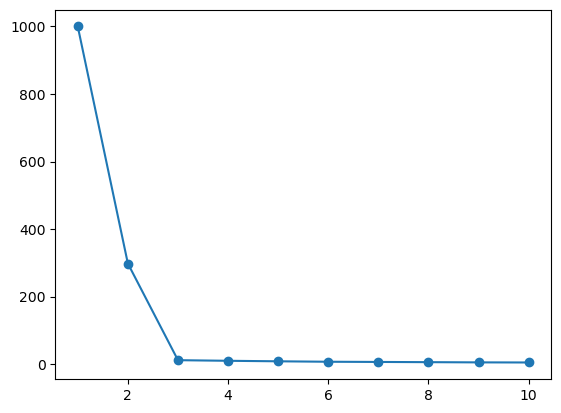

In [11]:
plt.plot(k_range,inertia,marker='o')

In [12]:
kmeans_final=KMeans(n_clusters=3,random_state=42)

In [13]:
cluster_labels=kmeans_final.fit_predict(X_scaled)

In [14]:
df['cluster']=cluster_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

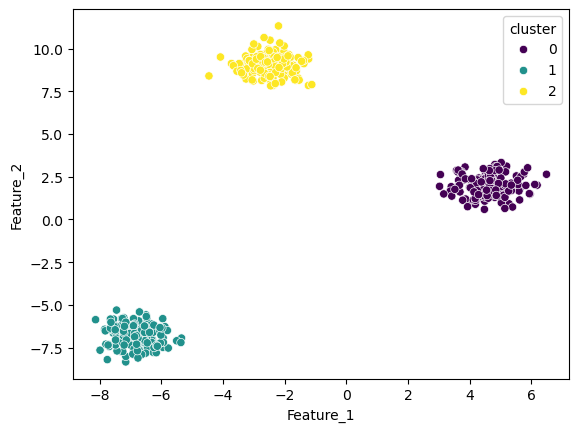

In [15]:
sns.scatterplot(x=df['Feature_1'],
               y=df['Feature_2'], 
               hue=df['cluster'], 
               palette='viridis')

In [16]:
from sklearn.datasets import make_moons

In [18]:
X,y_true=make_moons(n_samples=500,noise=0.05,random_state=42)

In [20]:
from sklearn.cluster import KMeans,DBSCAN

In [21]:
df=pd.DataFrame(X,columns=['Feature_1','Feature_2'])

In [22]:
df

,Feature_1,Feature_2
0,0.830586,-0.447733
1,0.701678,0.816918
2,1.022080,-0.492571
3,-0.316765,0.953438
4,0.293226,1.057185
...,...,...
495,0.239754,0.985462
496,0.072145,0.184834
497,0.590273,-0.365577
498,1.619465,-0.283658


In [23]:
X_scaled=scaler.fit_transform(df)

In [24]:
kmeans=KMeans(n_clusters=2,random_state=42)
kmeans_label=kmeans.fit_predict(X_scaled)

In [25]:
df['kmeans cluster']=kmeans_label

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

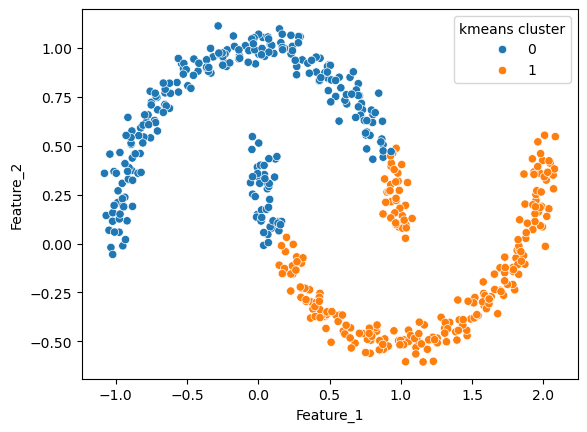

In [27]:
sns.scatterplot(x=df['Feature_1'],y=df['Feature_2'],
               hue=df['kmeans cluster'],palette='tab10')

In [28]:
dbscan=DBSCAN(eps=0.3,min_samples=5)
dbscan_labels=dbscan.fit_predict(X_scaled)

In [29]:
df['dbscan cluster']=dbscan_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

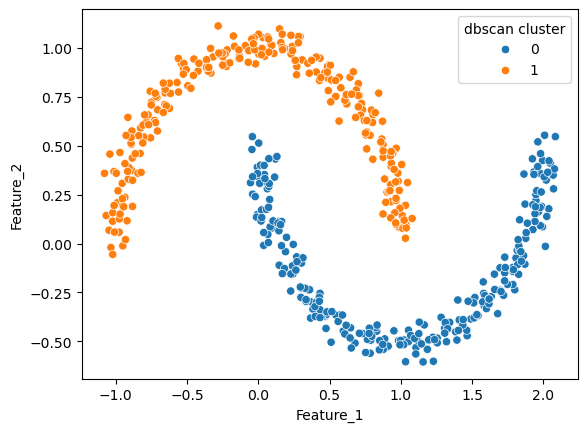

In [30]:
sns.scatterplot(x=df['Feature_1'],y=df['Feature_2'],
               hue=df['dbscan cluster'],palette='tab10')